# Assignment 8
Due Nov. 4

Yazdan Zinati 
260928077   

Dataset with brain atlas A: use the Oasis dataset for classification of male and female
individuals based on brain scans.

In [5]:
import numpy as np
from nilearn import datasets
from nilearn.input_data import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib


def fetch_oasis_dataset(n_rois):
    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
    yeo = datasets.fetch_atlas_schaefer_2018(
        n_rois=n_rois
    )  # this needs to be modified for some tasks
    print(
        "%i regions found in this atlas"
        % (len(np.unique(nib.load(yeo.maps).get_fdata().ravel())) - 1)
    )
    masker = NiftiLabelsMasker(
        labels_img=yeo.maps, standardize=True, memory="nilearn_cache"
    )
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = np.array(
        brain_data.ext_vars.mf == "F", dtype=int
    )  # gives 1 for females and 0 for males

    return input_variables, output_variable

Task 1- Build a learning curve. Using LogisticRegression(penalty=’l2’, C=1) and the lowest
resolution data (nrois=100), train a classification model on different subsets of the 100
subjects in increments of 10 (ie. Always using the 100 brain region features, and
10,20,…,90 subjects – you will have 9 different models). Next, evaluate each fitted LogReg
model on the unseen last 10 subject brain scans (these should be the same 10 subjects
across models). Plot the classification accuracy on the training set and the test set (x
axis=number of subjects (10-90), y axis=classification accuracy, 2 colors for two lines for
the 2 different metrics).

100 regions found in this atlas


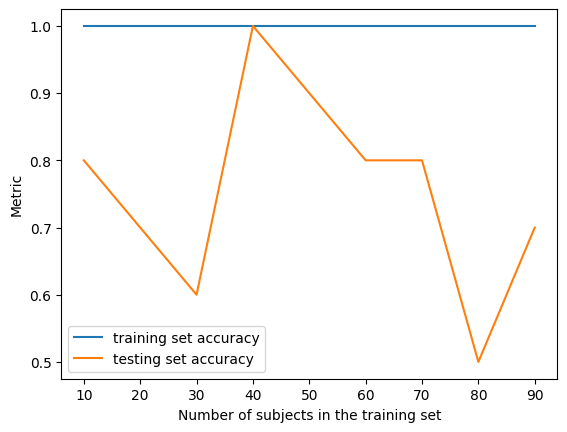

In [ ]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)


def task1(n_rois, plot_q3_metrics=False):
    num_subjects_range = range(10, 100, 10)
    accuracy_test = []
    accuracy_train = []
    precisions = []
    recalls = []
    f1s = []
    sensitivities = []
    specificities = []

    input_variables, output_variable = fetch_oasis_dataset(n_rois)

    input_test, output_test = input_variables[90:], output_variable[90:]
    for num_subjects in num_subjects_range:
        input_train, output_train = (
            input_variables[:num_subjects],
            output_variable[:num_subjects],
        )

        lr = LogisticRegression(penalty="l2", C=1)
        lr.fit(input_train, output_train)
        # accuracy_test.append(lr.score(input_test, output_test))
        # accuracy_train.append(lr.score(input_train, output_train))
        preds_test = lr.predict(input_test)
        accuracy_train.append(accuracy_score(output_train, lr.predict(input_train)))
        accuracy_test.append(accuracy_score(output_test, preds_test))
        precisions.append(precision_score(output_test, preds_test))
        recalls.append(recall_score(output_test, preds_test))
        f1s.append(f1_score(output_test, preds_test))

        cm = confusion_matrix(output_test, preds_test)
        tn, fp, fn, tp = cm.ravel()
        sensitivities.append(tp / (tp + fn))
        specificities.append(tn / (tn + fp))

    plt.figure()

    if plot_q3_metrics:
        plt.plot(list(num_subjects_range), precisions, label="precision")
        plt.plot(list(num_subjects_range), recalls, label="recall")
        plt.plot(list(num_subjects_range), f1s, label="f1")
        plt.plot(list(num_subjects_range), sensitivities, label="sensitivity")
        plt.plot(list(num_subjects_range), specificities, label="specificity")
    else:
        plt.plot(
            list(num_subjects_range), accuracy_train, label="training set accuracy"
        )
        plt.plot(list(num_subjects_range), accuracy_test, label="testing set accuracy")

    plt.ylabel("Metric")
    plt.xlabel("Number of subjects in the training set")
    plt.legend()
    plt.show()


task1(100)

Task 2- Same as 1 but using the highest atlas resolution (nrois=1000).

1000 regions found in this atlas


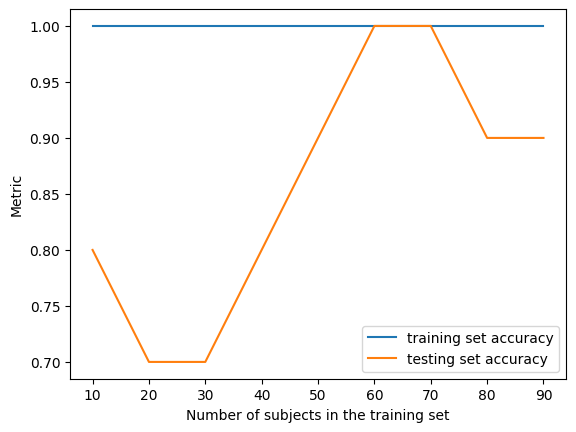

In [29]:
task1(1000)

Task 3- Building on task 1+2, plot other performance metrics instead of classification
accuracy. Using the same train/test set as Q1/2 with 100 ROIs (nrois=100), plot the
following test performance metrics: a) precision, b) recall, c) f1 score, d) sensitivity, and e)
specificity (5 lines with 5 colors, same axes as Q1/2).

100 regions found in this atlas


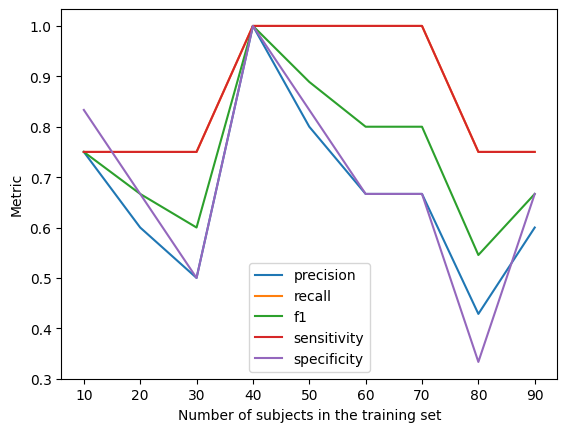

In [31]:
task1(100, plot_q3_metrics=True) # note that recall overlaps with sensitivity, they are the same

Task 4- Confusion matrix: similar to task 1 but using k-fold (k=10) cross-validation on 100
brain regions (nrois=100) to produce the characteristic 2x2 confusion matrix of actual-vs-
predicted label (model label prediction on test set vs true test set label). Aggregate the test
set predictions across the ten folds so that you have 100 (predicted label, true label) pairs.

100 regions found in this atlas


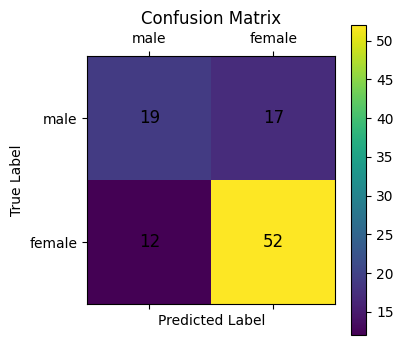

In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.model_selection import KFold


def task4_5(task=4):
    n_rois = 100
    k = 10
    input_variables, output_variable = fetch_oasis_dataset(n_rois)

    all_probs = [] # agg list of probabilities
    all_preds = []  # agg list of predictions
    all_true = []  # corresponding agg list of true labels

    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    for train_index, test_index in kf.split(input_variables):
        input_train, input_test = (
            input_variables[train_index],
            input_variables[test_index],
        )
        output_train, output_test = (
            output_variable[train_index],
            output_variable[test_index],
        )

        # Train logistic regression on the training fold
        lr = LogisticRegression(penalty="l2", C=1)
        lr.fit(input_train, output_train)

        # Predict on the test fold
        preds_test = lr.predict(input_test)
        probs_test = lr.predict_proba(input_test)[:, 1]


        # Append predictions and true labels to aggregate lists
        all_preds.extend(preds_test)
        all_probs.extend(probs_test)
        all_true.extend(output_test)

    if task == 4:
        cm = confusion_matrix(all_true, all_preds)
        tn, fp, fn, tp = cm.ravel()

        plt.figure(figsize=(4, 4))
        plt.matshow(cm, fignum=1)
        plt.title("Confusion Matrix")
        plt.colorbar()
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.xticks([0, 1], ["male", "female"])
        plt.yticks([0, 1], ["male", "female"])

        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                plt.text(
                    j,
                    i,
                    f"{cm[i, j]}",
                    ha="center",
                    va="center",
                    color="black",
                    fontsize=12,
                )

        plt.show()
    
    if task == 5:
        prob_true, prob_pred = calibration_curve(all_true, all_probs, n_bins=10)

        plt.figure(figsize=(8, 6))
        plt.plot(prob_pred, prob_true, marker="o", label="Logistic Regression", color="blue")
        plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
        plt.xlabel("Mean Predicted Probability")
        plt.ylabel("Fraction of Positives")
        plt.title("Calibration Plot (Logistic Regression)")
        plt.legend()
        plt.show()


task4_5()

Task 5- Calibration plot: Similar to task 1 but using k-fold (k=10) cross-validation on 100
brain regions to produce a calibration plot (requires predict_proba() function of LogReg(),
implemented in sklearn, looks like in lecture).

100 regions found in this atlas


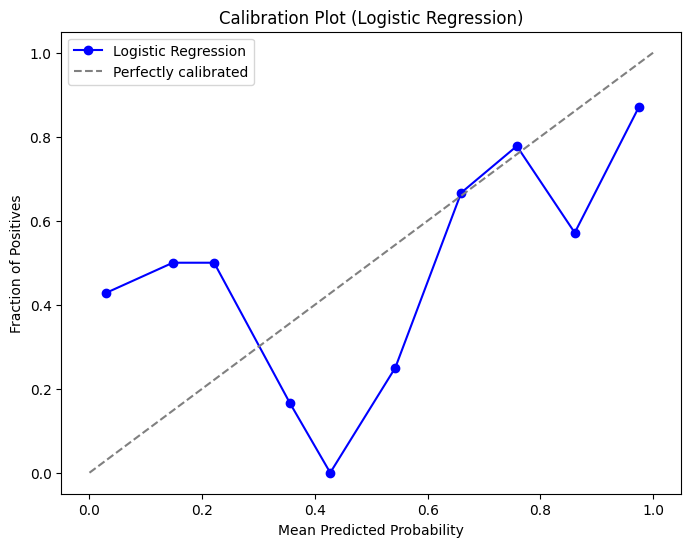

In [41]:
task4_5(task=5)

Dataset with brain atlas B: use the Oasis dataset to predict the continuous age based on
structural brain scans

In [43]:
import os

from sklearn.preprocessing import StandardScaler


def load_craddock_local(base_path):
    # Dictionary to hold the dataset information
    craddock_data = {
        "scorr_mean": os.path.join(base_path, "scorr05_mean_all.nii.gz"),
        "tcorr_mean": os.path.join(base_path, "tcorr05_mean_all.nii.gz"),
        "scorr_2level": os.path.join(base_path, "scorr05_2level_all.nii.gz"),
        "tcorr_2level": os.path.join(base_path, "tcorr05_2level_all.nii.gz"),
        "random": os.path.join(base_path, "random_all.nii.gz"),
        "description": "Craddock 2012 atlas parcellation dataset emphasizing spatial and temporal homogeneity.",
    }
    return craddock_data


def fetch_second_dataset(n_rois, debug=False):

    brain_data = datasets.fetch_oasis_vbm(n_subjects=100)

    brain_data_dir = "/home/yazdan/Yazdan/School/University/McGill Masters/third semester/BMDE520/McGill-BMDE520-Assignments/A3/craddock/"
    crad = load_craddock_local(brain_data_dir)

    atlas_nii = index_img(crad["scorr_mean"], n_rois)
    masker = NiftiLabelsMasker(labels_img=atlas_nii, standardize=True)
    input_variables = masker.fit_transform(brain_data.gray_matter_maps)
    output_variable = StandardScaler().fit_transform(brain_data.ext_vars.age[:, None])[
        :, 0
    ]  # gives subject age on standard units after z-scoring
    return input_variables, output_variable

Note: use Ridge() instead of LogisticRegression(), and coefficient of determination
(sklearn.metrics.r2_score) instead of accuracy.

6- analogous to task 1 but predicting continuous subject age and using the 1st / lowest-
resolution version of Craddock region atlas resolutions (.scorr_mean).

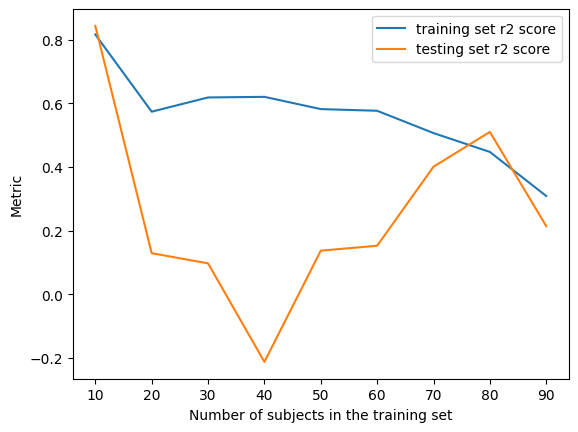

In [50]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, explained_variance_score, mean_squared_error

def task6(n_rois, plot_q8_metrics=False):
    num_subjects_range = range(10, 100, 10)
    r2_test = []
    r2_train = []
    mean_absolute_errors = []
    explained_variance_scores = []
    mean_squared_errors = []

    input_variables, output_variable = fetch_second_dataset(n_rois)

    input_test, output_test = input_variables[90:], output_variable[90:]
    for num_subjects in num_subjects_range:
        input_train, output_train = (
            input_variables[:num_subjects],
            output_variable[:num_subjects],
        )

        lr = Ridge()
        lr.fit(input_train, output_train)
        preds_test = lr.predict(input_test)
        preds_train = lr.predict(input_train)
        r2_train.append(r2_score(output_train, preds_train))
        r2_test.append(r2_score(output_test, preds_test))
        mean_absolute_errors.append(mean_absolute_error(output_test, preds_test))
        explained_variance_scores.append(explained_variance_score(output_test, preds_test))
        mean_squared_errors.append(mean_squared_error(output_test, preds_test))

    plt.figure()

    plt.plot(
        list(num_subjects_range), r2_train, label="training set r2 score"
    )
    plt.plot(list(num_subjects_range), r2_test, label="testing set r2 score")
    if plot_q8_metrics:
        plt.plot(list(num_subjects_range), mean_absolute_errors, label="mean absolute error")
        plt.plot(list(num_subjects_range), explained_variance_scores, label="explained variance score")
        plt.plot(list(num_subjects_range), mean_squared_errors, label="mean squared error")

    plt.ylabel("Metric")
    plt.xlabel("Number of subjects in the training set")
    plt.legend()
    plt.show()


task6(n_rois=0) # the lowest res of the dataset

7- analogous to task 2 but predicting continuous subject age and using the last / finest-
grained-resolution version of Craddock region atlas resolutions (.scorr_mean).

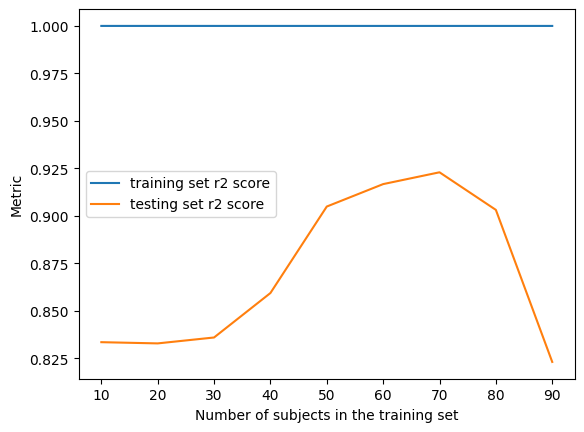

In [51]:
task6(n_rois=42) # the highest res of the dataset

8- analogous to task 3 but plotting outcome metrics suited to continuous outcomes: a) r2
score, b) mean absolute error and c) explained variance score, as well as d) mean-squared
error.

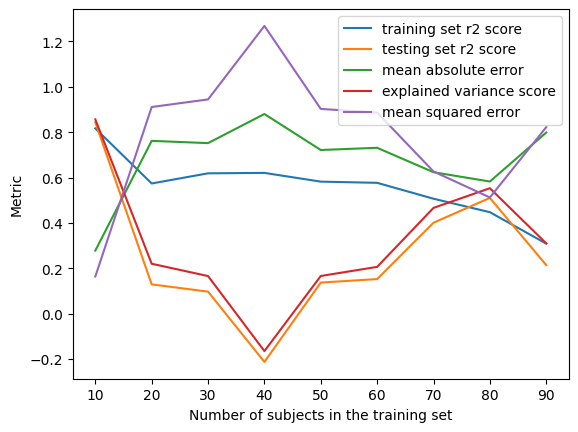

In [52]:
task6(n_rois=0, plot_q8_metrics=True)

9- analogous to task 4, median-splitting the continuous outcome (that is, computing median
of outcome across ages on the full sample of participants, then classifying predictions into
high-age vs. low-age on the test participants), then produce a confusion matrix in similar
manner for a 2x2 confusion matrix of actual vs. predicted high- vs. low-age.

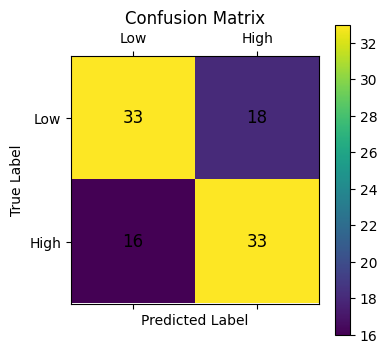

In [62]:
def task9_10(task=9):
    n_rois = 0
    k = 10
    input_variables, output_variable = fetch_second_dataset(n_rois)

    all_probs = [] # agg list of probabilities
    all_preds = []  # agg list of predictions
    all_true = []  # corresponding agg list of true labels

    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    for train_index, test_index in kf.split(input_variables):
        input_train, input_test = (
            input_variables[train_index],
            input_variables[test_index],
        )
        output_train, output_test = (
            output_variable[train_index],
            output_variable[test_index],
        )

        # Train logistic regression on the training fold
        ridge = Ridge()
        lr = LogisticRegression(penalty="l2", C=1)
        ridge.fit(input_train, output_train)


        median_value = np.median(output_variable)
        output_train_binary = np.where(output_train >= median_value, 1, 0)
        lr.fit(input_train, output_train_binary)

        # Predict on the test fold
        preds_test = ridge.predict(input_test)
        probs_test = lr.predict_proba(input_test)[:, 1]


        # Append predictions and true labels to aggregate lists
        all_preds.extend(preds_test)
        all_probs.extend(probs_test)
        all_true.extend(output_test)

    if task == 9:
        classified_array_real = np.where(all_true >= median_value, 'high-age', 'low-age')
        classified_array_pred = np.where(all_preds >= median_value, 'high-age', 'low-age')

        cm = confusion_matrix(classified_array_real, classified_array_pred)
        tn, fp, fn, tp = cm.ravel()

        plt.figure(figsize=(4, 4))
        plt.matshow(cm, fignum=1)
        plt.title("Confusion Matrix")
        plt.colorbar()
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.xticks([0, 1], ["Low", "High"])
        plt.yticks([0, 1], ["Low", "High"])

        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                plt.text(
                    j,
                    i,
                    f"{cm[i, j]}",
                    ha="center",
                    va="center",
                    color="black",
                    fontsize=12,
                )

        plt.show()
    
    if task == 10:
        prob_true, prob_pred = calibration_curve(np.where(all_true >= median_value, 1, 0), all_probs, n_bins=10)

        plt.figure(figsize=(8, 6))
        plt.plot(prob_pred, prob_true, marker="o", label="Logistic Regression", color="blue")
        plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
        plt.xlabel("Mean Predicted Probability")
        plt.ylabel("Fraction of Positives")
        plt.title("Calibration Plot (Logistic Regression)")
        plt.legend()
        plt.show()


task9_10()

10- analogous to task 5, but using age prediction (since the target is continuous, divide into
high-age vs. low-age groups and use LogisticRegression() as in Q5).

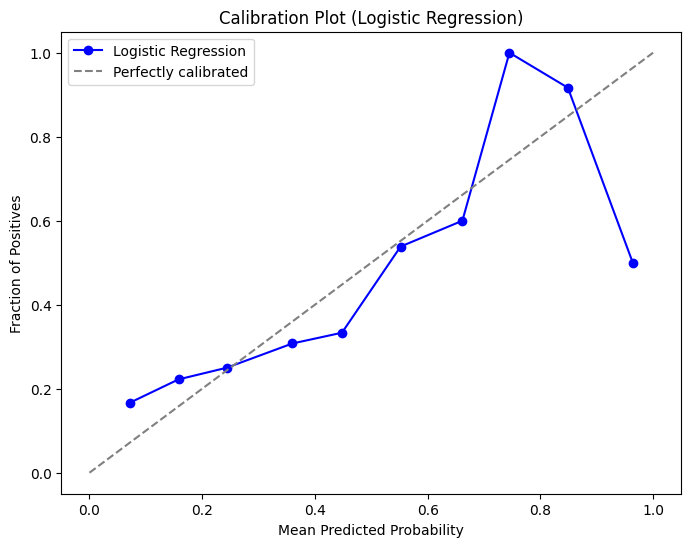

In [63]:
task9_10(task=10)